In [1]:
import numpy as np
import xarray as xr

proc = "../data/processed"
rain = xr.open_dataset(f"{proc}/rain_daily_box.nc")["rain"]
temp = xr.open_dataset(f"{proc}/temp_daily_box.nc")

pr_m = rain.resample(time="MS").sum(min_count=1)     # mm/month
tx_m = temp["tmax"].resample(time="MS").mean()       # °C
tn_m = temp["tmin"].resample(time="MS").mean()
print(pr_m.sizes["time"], tx_m.sizes["time"], "months (expect 516 each)")

516 516 months (expect 516 each)


In [2]:
tx_r = tx_m.interp(lat=pr_m.lat, lon=pr_m.lon, method="linear")
tn_r = tn_m.interp(lat=pr_m.lat, lon=pr_m.lon, method="linear")
tmean = (tx_r + tn_r) / 2

In [3]:
mask = xr.open_dataarray(f"{proc}/marathwada_mask_025.nc").any("region")
m = mask.reindex_like(pr_m, method="nearest", tolerance=0.01).fillna(False).astype(bool)

ds = xr.Dataset({"pr": pr_m, "tmax": tx_r, "tmin": tn_r, "tmean": tmean}).where(m)
ds = ds.dropna("lat", how="all").dropna("lon", how="all")   # trim to Marathwada's box

ds["pr"].attrs.update(units="mm/month", long_name="monthly precipitation")
for v in ["tmax", "tmin", "tmean"]:
    ds[v].attrs["units"] = "degC"
ds.attrs.update(
    period="1981-2023",
    source="IMD 0.25 deg rainfall (Pai et al. 2014); IMD 1 deg Tmax/Tmin (Srivastava et al. 2009), "
           "monthly means bilinearly interpolated to 0.25 deg; tmean = (tmax + tmin) / 2",
)
ds.to_netcdf(f"{proc}/marathwada_monthly_025.nc")
print(ds)

<xarray.Dataset> Size: 3MB
Dimensions:  (time: 516, lat: 12, lon: 15)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-01-01 1981-02-01 ... 2023-12-01
  * lat      (lat) float64 96B 17.75 18.0 18.25 18.5 ... 19.75 20.0 20.25 20.5
  * lon      (lon) float64 120B 74.75 75.0 75.25 75.5 ... 77.5 77.75 78.0 78.25
Data variables:
    pr       (time, lat, lon) float64 743kB nan nan nan nan ... nan nan nan nan
    tmax     (time, lat, lon) float64 743kB nan nan nan nan ... nan nan nan nan
    tmin     (time, lat, lon) float64 743kB nan nan nan nan ... nan nan nan nan
    tmean    (time, lat, lon) float64 743kB nan nan nan nan ... nan nan nan nan
Attributes:
    period:   1981-2023
    source:   IMD 0.25 deg rainfall (Pai et al. 2014); IMD 1 deg Tmax/Tmin (S...


In [4]:
inside = ds["pr"].notnull().any("time")
print(int(inside.sum()), "cells with data (expect 91)")
for v in ["pr", "tmax", "tmin", "tmean"]:
    print(v, int((ds[v].isnull() & inside).sum()), "missing cell-months inside (expect 0)")

w = np.cos(np.deg2rad(ds.lat))                         # cell area shrinks with latitude
reg = ds[["pr", "tmax", "tmin", "tmean"]].weighted(w).mean(("lat", "lon"))

annual = reg["pr"].resample(time="YS").sum()
print(annual.to_series().round(0).describe())
jjas = reg["pr"].where(reg["pr"].time.dt.month.isin([6, 7, 8, 9])).sum() / reg["pr"].sum()
print(f"June–September share of rainfall: {float(jjas):.0%}")
print(reg.groupby("time.month").mean().to_dataframe().round(1))

91 cells with data (expect 91)
pr 0 missing cell-months inside (expect 0)
tmax 0 missing cell-months inside (expect 0)
tmin 0 missing cell-months inside (expect 0)
tmean 0 missing cell-months inside (expect 0)
count      43.000000
mean      812.953488
std       193.893804
min       552.000000
25%       645.500000
50%       791.000000
75%       929.500000
max      1246.000000
Name: pr, dtype: float64
June–September share of rainfall: 83%
          pr  tmax  tmin  tmean
month                          
1        4.8  30.1  13.8   21.9
2        2.7  32.9  15.8   24.3
3        9.1  36.7  19.5   28.1
4        7.7  39.8  23.3   31.5
5       14.3  40.6  25.4   33.0
6      138.3  35.5  24.0   29.8
7      191.6  31.1  22.7   26.9
8      179.1  30.1  22.0   26.1
9      168.2  31.3  21.8   26.5
10      77.6  32.4  19.8   26.1
11      14.3  31.1  16.3   23.7
12       5.2  29.8  13.7   21.7


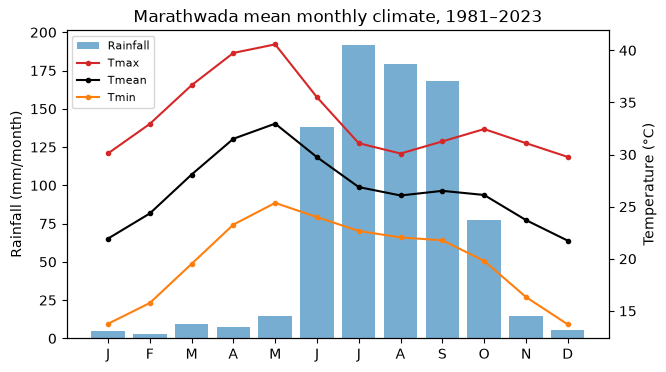

In [5]:
import matplotlib.pyplot as plt

reg.to_dataframe().round(2).to_csv("../outputs/tables/marathwada_monthly_regional.csv")

clim = reg.groupby("time.month").mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(clim.month, clim.pr, color="tab:blue", alpha=0.6, label="Rainfall")
ax.set_ylabel("Rainfall (mm/month)")
ax2 = ax.twinx()
for v, c in [("tmax", "tab:red"), ("tmean", "k"), ("tmin", "tab:orange")]:
    ax2.plot(clim.month, clim[v], color=c, marker="o", ms=3, label=v.capitalize())
ax2.set_ylabel("Temperature (°C)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(list("JFMAMJJASOND"))
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax.set_title("Marathwada mean monthly climate, 1981–2023")
fig.savefig("../outputs/figures/fig02_climograph.png", dpi=300, bbox_inches="tight")